# NetMind ML demo

End-to-end story for Phase 6: generated simulation windows → features → anomaly detection (z-score detector, compared against IsolationForest) → plots → applying the saved detectors to the S2 link-failure demo scenario.

Prerequisites: `build/release/netmind_cli.exe` (or `build/release/netmind_cli`) and the window dataset:

```
python -m ml.generate_dataset --cli ../build/release/netmind_cli --topologies ../config/topologies/medium10.json ../config/topologies/ring_backup.json ../config/topologies/dumbbell.json ../config/topologies/diamond_weighted.json --output ../data/windows_dataset --max-runs 400 --duration 30 --packet-bytes 1500 --workers 8 --discard-runs
```

In [1]:
import json, subprocess, sys, tempfile
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python" / "ml").is_dir())
sys.path.insert(0, str(ROOT / "python"))

import pandas as pd
from IPython.display import Image, display
from ml import anomaly, features, plots
from ml.generate_dataset import label_windows
from common.io import read_windows

DATASET = ROOT / "data" / "windows_dataset"
PLOTS = ROOT / "data" / "plots"
MODELS = ROOT / "data" / "models"
PLOTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

## 1. Dataset
One row per simulated second. `is_anomaly` is the ground truth: the window overlaps an injected disturbance (failure → restore, congestion or burst duration).

In [2]:
windows = features.load_windows(DATASET / "windows_all.csv")
runs = pd.read_csv(DATASET / "runs_all.csv")
print(f"{runs['run_id'].nunique()} runs, {len(windows)} windows")
windows.groupby("event_pattern").agg(runs=("run_id", "nunique"), windows=("t_start", "size"), anomalous_share=("is_anomaly", "mean"))

400 runs, 12400 windows


,runs,windows,anomalous_share
event_pattern,,,
burst,82,2542,0.293
congestion,85,2635,0.297
link_failure,84,2604,0.336
none,79,2449,0.000
router_failure,70,2170,0.338


## 2. Features (6.3)
Per-window metrics plus causal change features: one- and three-window deltas, deviation from the previous three-window mean, and deviation from the run's own expanding median. Changes are divided by the run's reference level so runs with different loads are comparable. `active_failures` is excluded because it encodes the injected event directly (label leakage).

In [3]:
frame = features.build_window_features(windows)
columns = features.feature_columns(frame)
print(len(columns), "features")
frame[["run_id", "t_start", "avg_latency_ms", "avg_latency_ms_vs_ref", "loss_pct", "loss_pct_delta1", "is_anomaly"]].head(8)

31 features


,run_id,t_start,avg_latency_ms,avg_latency_ms_vs_ref,loss_pct,loss_pct_delta1,is_anomaly
0,run_001,0.0,10.72,0.0,0.0,0.0,0
1,run_001,1.0,10.72,0.0,0.0,0.0,0
2,run_001,2.0,10.72,0.0,0.0,0.0,0
3,run_001,3.0,10.72,0.0,0.0,0.0,0
4,run_001,4.0,10.72,0.0,0.0,0.0,0
5,run_001,5.0,10.72,0.0,0.0,0.0,0
6,run_001,6.0,10.72,0.0,0.0,0.0,0
7,run_001,7.0,10.72,0.0,0.0,0.0,0


## 3. Anomaly detection (6.4)
Runs are split 60/20/20 (train/validation/test) by run id, so no run contributes to two splits. Both detectors are fitted on windows from **normal training runs only**; each threshold is chosen by maximum F1 on validation runs; scores below are on held-out test runs.

- **z-score (primary detector):** a window's score is its largest |z| across features. It flags a window when any single metric moves far outside its normal range.
- **IsolationForest (ML comparison):** the model the plan asked for. It scores how unusual a window looks across all features at once.
- **Fixed |z| > 3:** the plan's untuned rule, shown for reference.

On this dataset the z-score wins: higher F1 and far fewer false alarms on clean runs. Failures here usually show up as one metric jumping, which is exactly what the z-score checks, while IsolationForest also flags steady windows that merely look unusual next to the varied normal runs.

In [4]:
results, scored = anomaly.run_experiment(windows, seed=42, models_dir=MODELS)
summary = pd.DataFrame({name: {**m["test"], **m["test_runs"]} for name, m in results["models"].items()}).T
summary[["precision", "recall", "f1", "detection_rate", "clean_window_false_alarm_rate"]]

,precision,recall,f1,detection_rate,clean_window_false_alarm_rate
zscore,0.599,0.584,0.592,0.794,0.027
isolation_forest,0.393,0.711,0.507,0.873,0.205
zscore_fixed_3sigma,0.429,0.739,0.543,0.889,0.161


In [5]:
pd.DataFrame({name: m["test_recall_by_pattern"] for name, m in results["models"].items()})

,zscore,isolation_forest,zscore_fixed_3sigma
burst,0.699,0.908,0.902
congestion,0.459,0.635,0.655
link_failure,0.529,0.571,0.635
router_failure,0.669,0.754,0.780


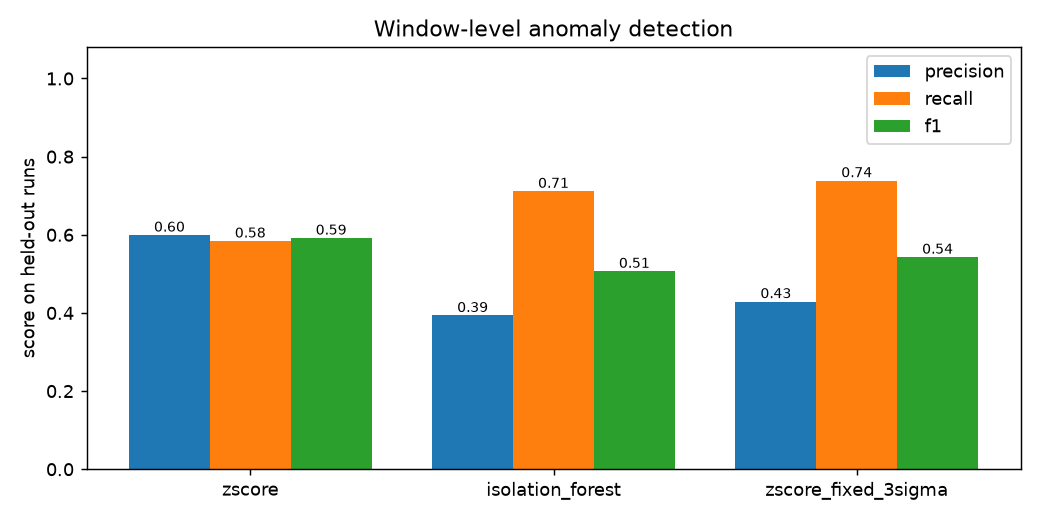

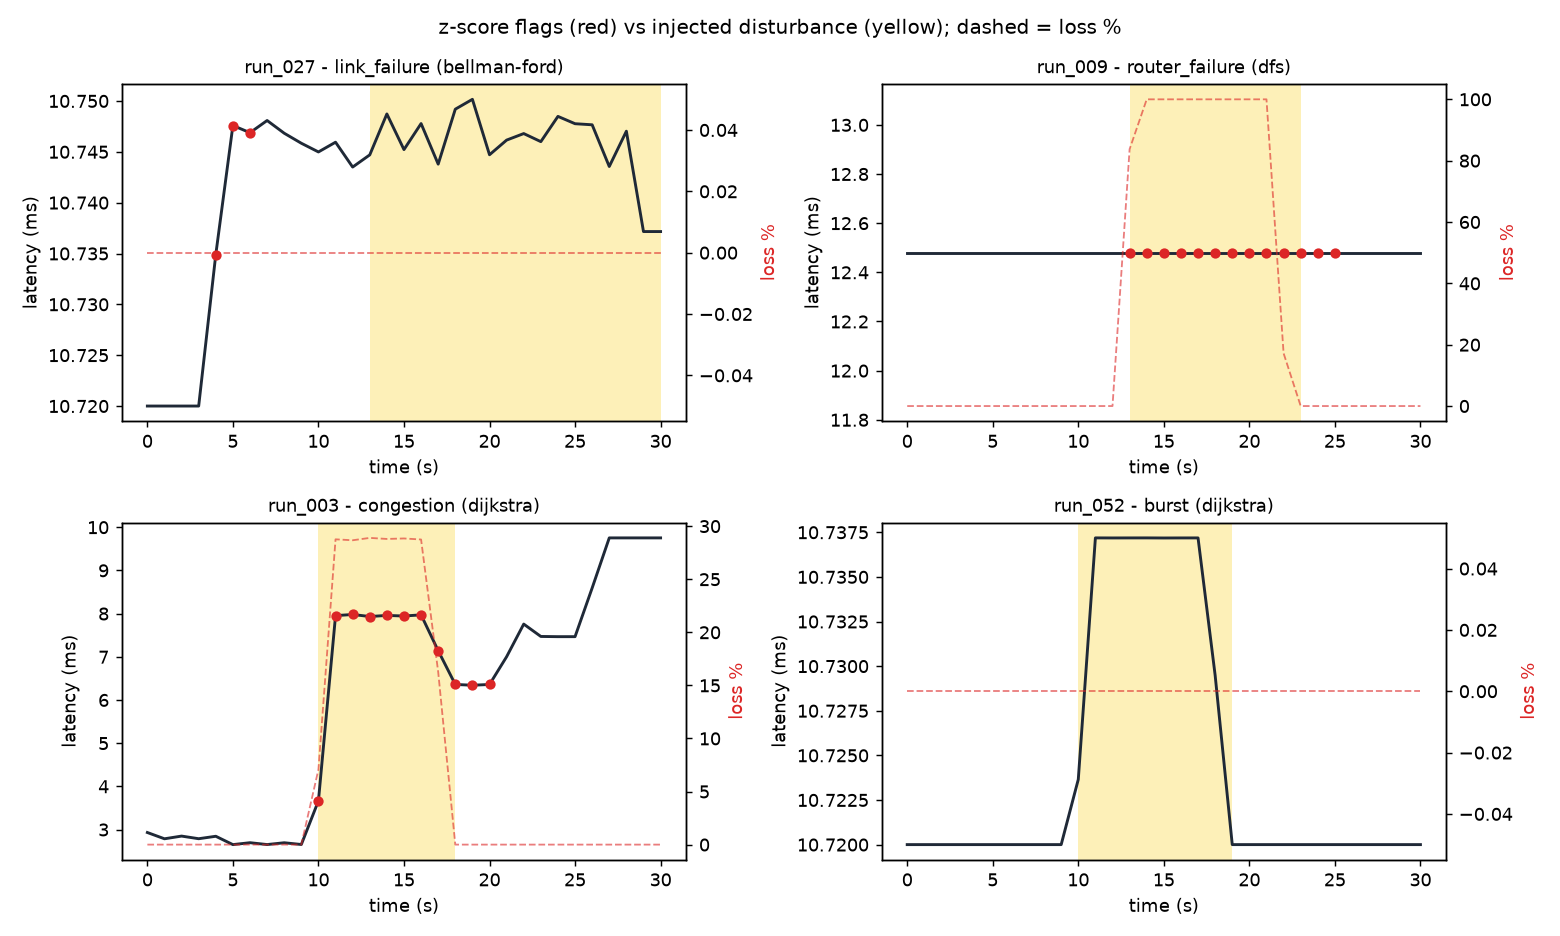

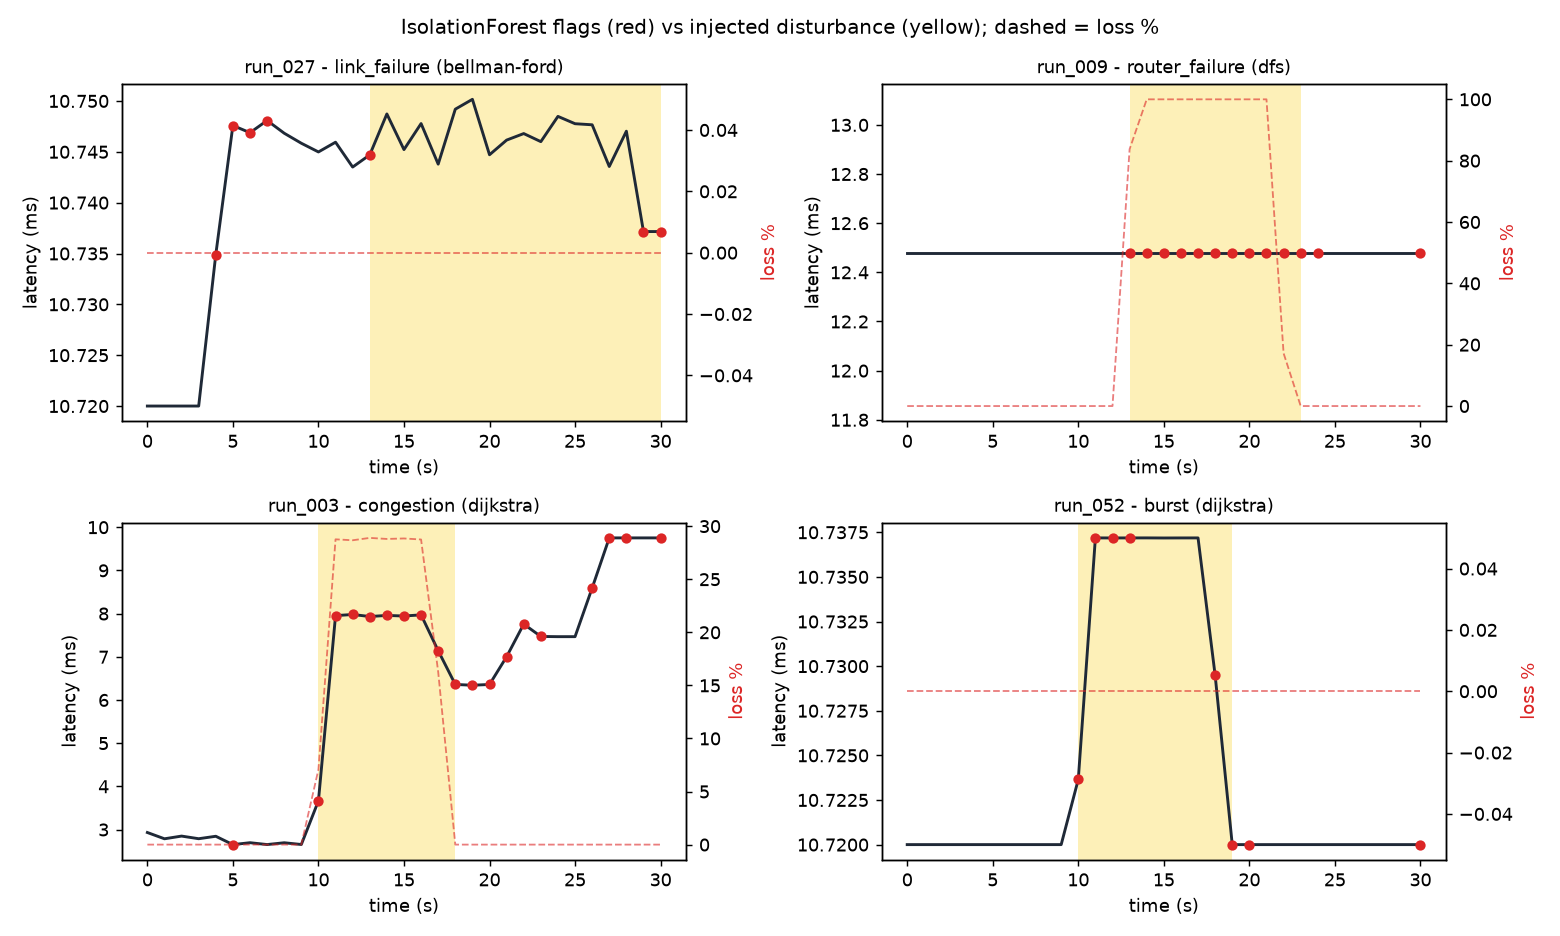

In [6]:
plots.plot_anomaly_comparison(results, PLOTS / "anomaly_f1_comparison.png")
plots.plot_anomaly_timeline(scored, PLOTS / "anomaly_timeline.png", "zscore_flag", "z-score")
plots.plot_anomaly_timeline(scored, PLOTS / "anomaly_timeline_isolation_forest.png", "isolation_forest_flag", "IsolationForest")
display(Image(PLOTS / "anomaly_f1_comparison.png"), Image(PLOTS / "anomaly_timeline.png"), Image(PLOTS / "anomaly_timeline_isolation_forest.png"))

## 4. Algorithm comparison (6.7)
Means over the generated runs. Topology, load and event are sampled at random per run, so treat this as descriptive; the controlled comparison is `compare` / the S2 scenarios below.

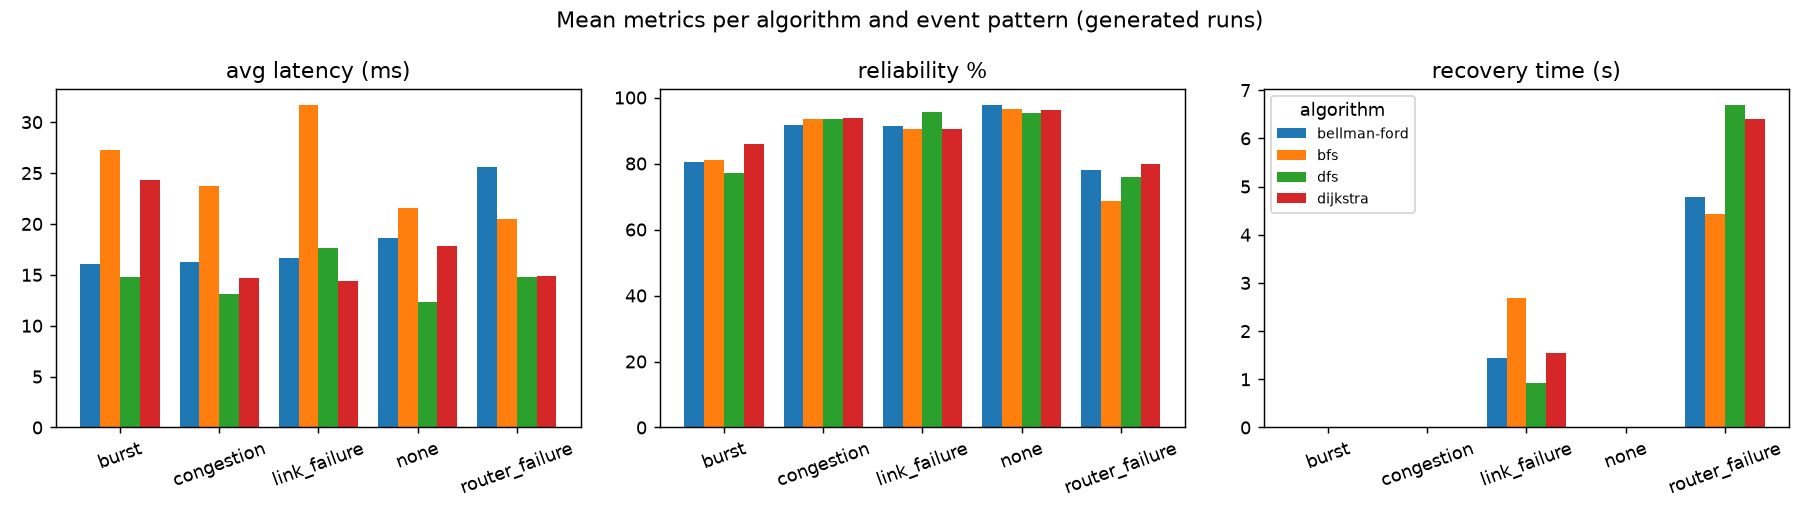

In [7]:
plots.plot_algorithm_comparison(runs, PLOTS / "algorithm_comparison.png")
display(Image(PLOTS / "algorithm_comparison.png"))

## 5. Demo scenario S2: does the trained detector catch the link failure?
Runs the S2 scenario (ring_backup, R1–R2 fails at 20 s, restores at 40 s) with Dijkstra (0.2 s reconvergence) and Bellman-Ford (3 s), then applies both saved detectors (top row: the primary z-score detector; bottom row: IsolationForest for comparison).

In [8]:
cli = next((p for p in [ROOT / "build/release/netmind_cli.exe", ROOT / "build/release/netmind_cli"] if p.is_file()), None)
bundle = anomaly.joblib.load(MODELS / anomaly.BUNDLE_NAME)
demo = {}
if cli is None:
    print("Build the C++ CLI first (cmake --preset release && cmake --build --preset release)")
else:
    for name in ("s2_link_failure_dijkstra", "s2_link_failure_bellman_ford"):
        scenario_path = ROOT / "config/scenarios" / f"{name}.json"
        scenario = json.loads(scenario_path.read_text())
        with tempfile.TemporaryDirectory() as out:
            subprocess.run([str(cli), "--scenario", str(scenario_path), "--out", out, "--quiet"], check=True)
            w = read_windows(Path(out) / "run_001_windows.csv")
        w.insert(0, "run_id", name)
        w["algorithm"], w["event_pattern"] = scenario["routing"]["algorithm"], "link_failure"
        w["is_anomaly"] = label_windows(w, scenario["events"], scenario["duration_s"])
        demo[name] = anomaly.flag_windows(bundle, w)

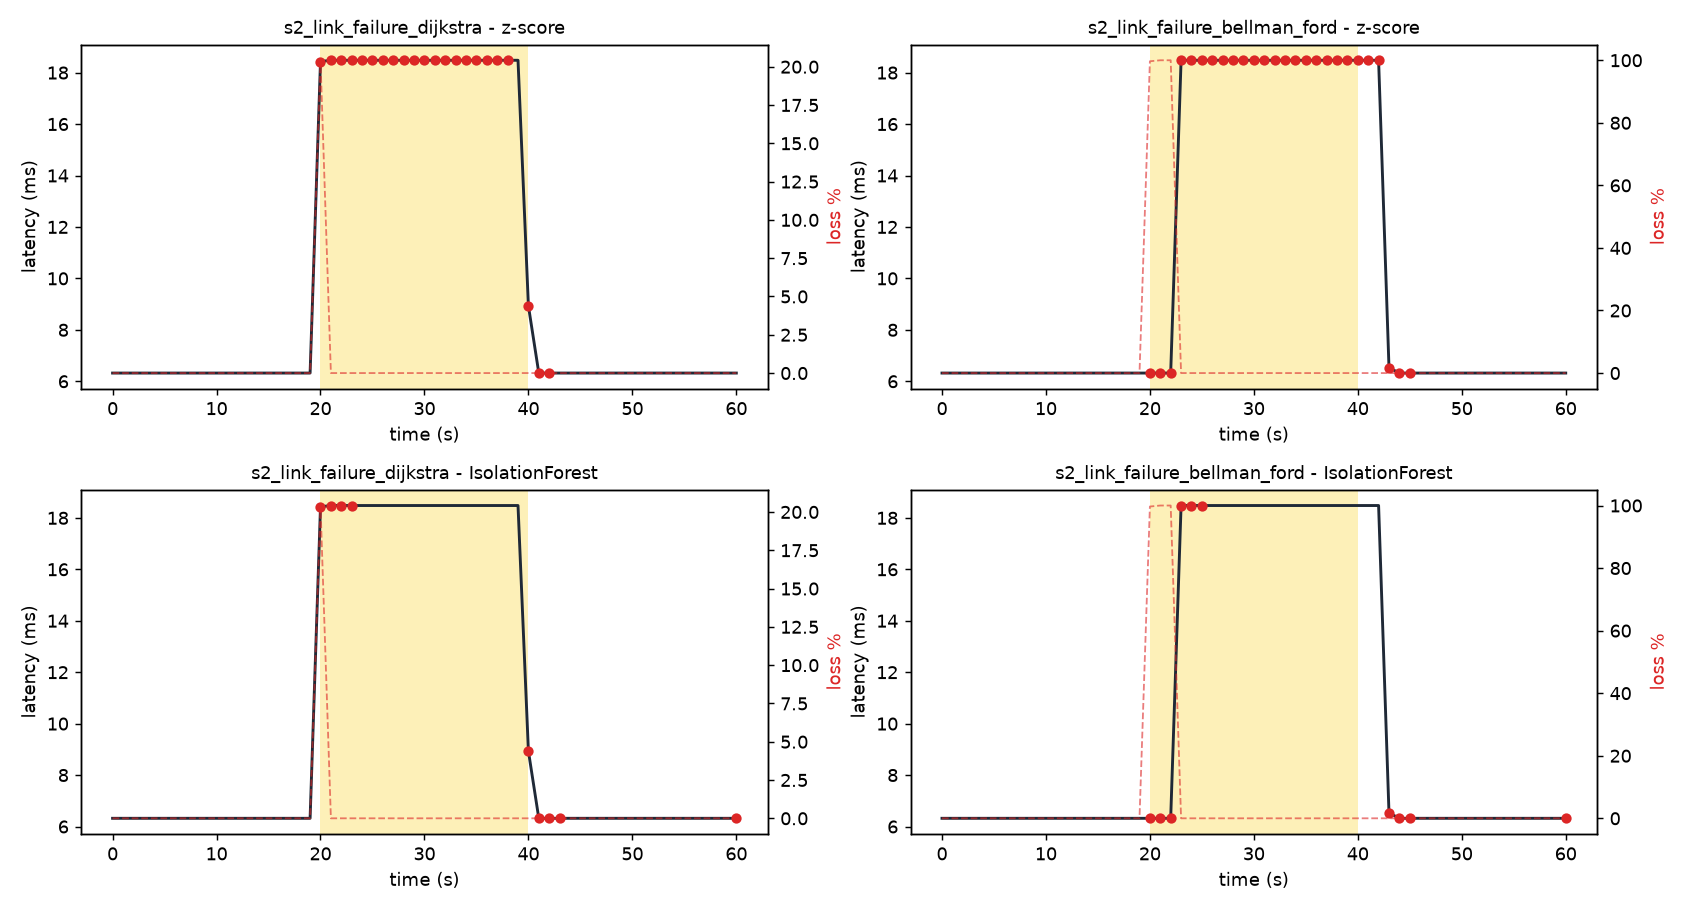

s2_link_failure_dijkstra [z-score]: flagged t = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 40, 41, 42]
s2_link_failure_dijkstra [IsolationForest]: flagged t = [20, 21, 22, 23, 40, 41, 42, 43, 60]
s2_link_failure_bellman_ford [z-score]: flagged t = [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45]
s2_link_failure_bellman_ford [IsolationForest]: flagged t = [20, 21, 22, 23, 24, 25, 43, 44, 45, 60]


In [9]:
import matplotlib.pyplot as plt
if demo:
    detectors = [("zscore_flag", "z-score"), ("isolation_forest_flag", "IsolationForest")]
    fig, axes = plt.subplots(2, len(demo), figsize=(13, 7), squeeze=False)
    for row, (flag, label) in enumerate(detectors):
        for col, (name, run) in enumerate(demo.items()):
            plots.plot_run_anomalies(axes[row][col], run, flag, f"{name} - {label}")
    fig.tight_layout(); fig.savefig(PLOTS / "s2_anomaly_flags.png", dpi=130); plt.close(fig)
    display(Image(PLOTS / "s2_anomaly_flags.png"))
    for name, run in demo.items():
        for flag, label in detectors:
            flagged = run.loc[run[flag], "t_start"].astype(int).tolist()
            print(f"{name} [{label}]: flagged t = {flagged}")

## Caveats
- The plan's goal was for the ML model to beat the z-score baseline; on this dataset it does not, so the simpler z-score is the detector NetMind uses.
- Labels mark the whole injected interval. A failure that is rerouted instantly, or that hits a link no flow uses, has labelled windows with no visible effect, which caps achievable recall (see recall by pattern).
- The dataset uses four hand-built topologies; results may not transfer to other topologies.